In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


In [2]:
data = pd.read_csv('/content/Mall_Customers.csv')

In [3]:
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [8]:
data.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [10]:
data.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [13]:
data.duplicated().sum()

np.int64(0)

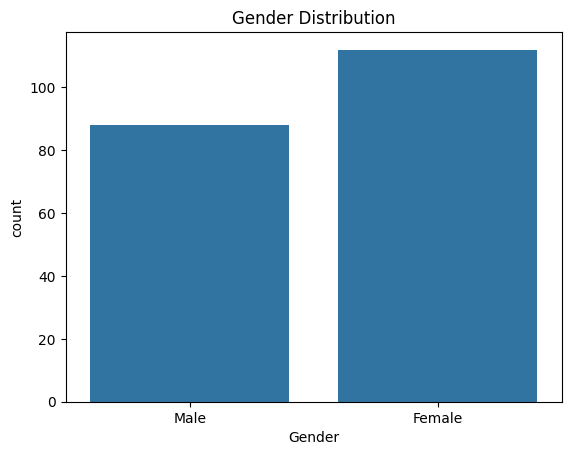

In [15]:
sns.countplot(data=data, x='Gender')

plt.title('Gender Distribution')
plt.show()

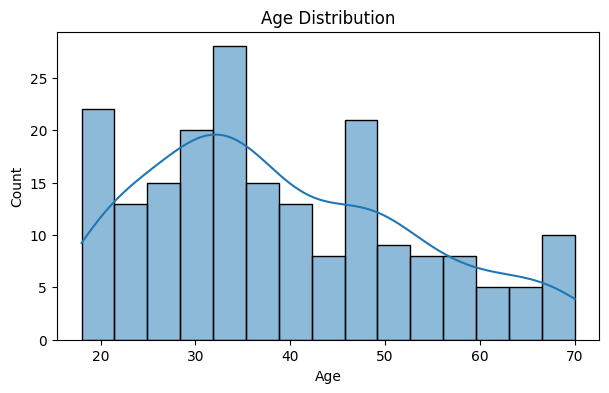

In [16]:
plt.figure(figsize=(7,4))

sns.histplot(data['Age'], bins=15, kde=True)

plt.title('Age Distribution')
plt.show()

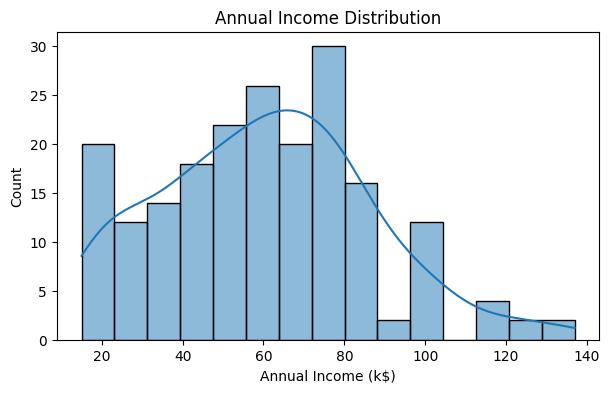

In [17]:
plt.figure(figsize=(7,4))

sns.histplot(data['Annual Income (k$)'], bins=15, kde=True)

plt.title('Annual Income Distribution')
plt.show()

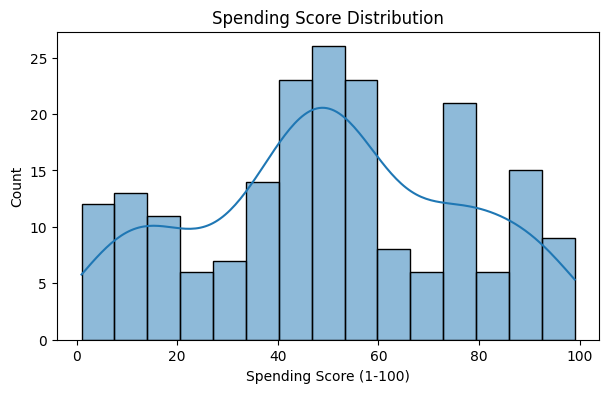

In [18]:
plt.figure(figsize=(7,4))

sns.histplot(data['Spending Score (1-100)'], bins=15, kde=True)

plt.title('Spending Score Distribution')
plt.show()

In [19]:
x = data[['Annual Income (k$)', 'Spending Score (1-100)']]

x.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [20]:
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

In [24]:
wcss = []

for i in range(1, 11):

    km = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    km.fit(x_scaled)

    wcss.append(km.inertia_)

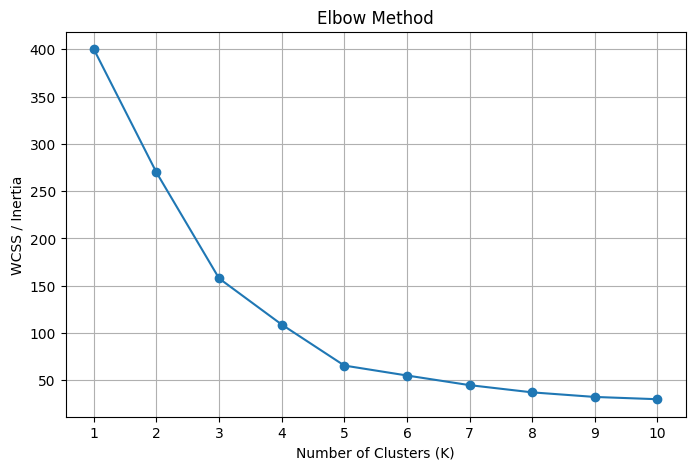

In [25]:
plt.figure(figsize=(8,5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS / Inertia')

plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [26]:
for i in range(2, 11):

    km = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)

    print("Clusters:", i, "| Silhouette Score:", score)

Clusters: 2 | Silhouette Score: 0.3212707813918878
Clusters: 3 | Silhouette Score: 0.46658474419000145
Clusters: 4 | Silhouette Score: 0.4939069237513199
Clusters: 5 | Silhouette Score: 0.5546571631111091
Clusters: 6 | Silhouette Score: 0.5398800926790663
Clusters: 7 | Silhouette Score: 0.5281492781108291
Clusters: 8 | Silhouette Score: 0.4552147906587443
Clusters: 9 | Silhouette Score: 0.4570853966942764
Clusters: 10 | Silhouette Score: 0.4431713026508046


In [31]:
optimal_k = 5
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(x_scaled)

data['Cluster'] = clusters


In [32]:
data[['CustomerID', 'Annual Income (k$)',
      'Spending Score (1-100)', 'Cluster']].head(10)

,CustomerID,Annual Income (k$),Spending Score (1-100),Cluster
0,1,15,39,4
1,2,15,81,2
2,3,16,6,4
3,4,16,77,2
4,5,17,40,4
5,6,17,76,2
6,7,18,6,4
7,8,18,94,2
8,9,19,3,4
9,10,19,72,2


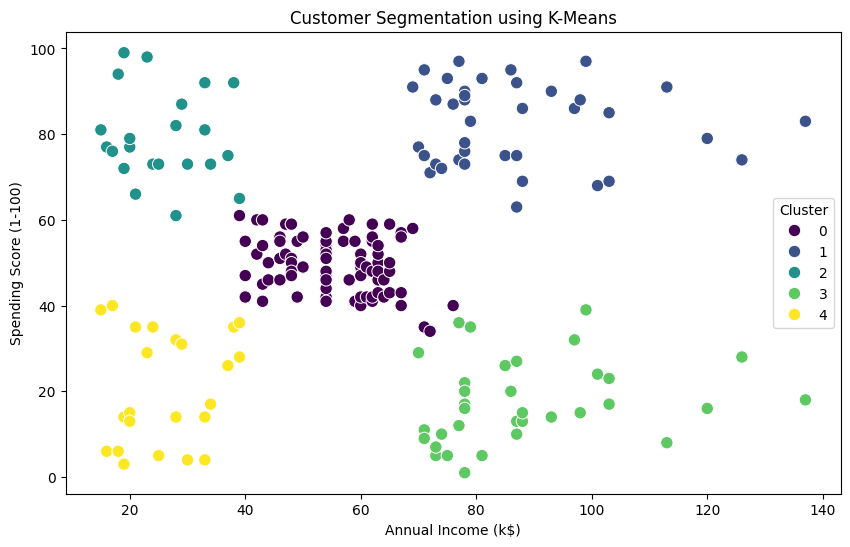

In [33]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x=x['Annual Income (k$)'],
    y=x['Spending Score (1-100)'],
    hue=data['Cluster'],
    palette='viridis',
    s=80
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.legend(title='Cluster')
plt.show()

In [36]:
cluster_analysis = data.groupby('Cluster').agg({
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean',
    'CustomerID': 'count'
})

cluster_analysis.rename(
    columns={'CustomerID': 'Customer Count'},
    inplace=True
)

print(cluster_analysis.round(2))

           Age  Annual Income (k$)  Spending Score (1-100)  Customer Count
Cluster                                                                   
0        42.72               55.30                   49.52              81
1        32.69               86.54                   82.13              39
2        25.27               25.73                   79.36              22
3        41.11               88.20                   17.11              35
4        45.22               26.30                   20.91              23


In [37]:
print("Customer Segmentation Completed")

print("Total Customers:", len(data))
print("Number of Clusters:", optimal_k)

print("\nCustomer Count in Each Cluster:")
print(data['Cluster'].value_counts().sort_index())

Customer Segmentation Completed
Total Customers: 200
Number of Clusters: 5

Customer Count in Each Cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
